In [15]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import xarray as xr
 
from src import pet, indices as ix, scenarios as sc, trends
 
proc = "../data/processed"
ds = xr.open_dataset(f"{proc}/marathwada_monthly_025.nc")
inside = ds["pr"].notnull().any("time")
w = np.cos(np.deg2rad(ds.lat)) * inside
reg = lambda x: x.weighted(w).mean(("lat", "lon"))

In [16]:
I_obs = pet.heat_index(ds["tmean"])
annual = lambda x: float(reg(x).groupby("time.year").sum().mean())
base_th = annual(pet.thornthwaite(ds["tmean"], I=I_obs))
base_hg = annual(pet.hargreaves(ds["tmax"], ds["tmin"]))
 
for dt in (1, 2, 4):
    fx = annual(pet.thornthwaite(ds["tmean"] + dt, I=I_obs))
    rc = annual(pet.thornthwaite(ds["tmean"] + dt))
    hg = annual(pet.hargreaves(ds["tmax"] + dt, ds["tmin"] + dt))
    print(f"+{dt} C step: Th fixed I {100*(fx/base_th-1):+.1f}%  "
          f"Th recomputed I {100*(rc/base_th-1):+.1f}%  Hg {100*(hg/base_hg-1):+.1f}%")

+1 C step: Th fixed I +14.3%  Th recomputed I +16.0%  Hg +2.2%
+2 C step: Th fixed I +30.0%  Th recomputed I +36.7%  Hg +4.5%
+4 C step: Th fixed I +66.2%  Th recomputed I +99.8%  Hg +8.9%


In [17]:
z0 = sc.spei_scenario("th_fixed", ds, 0.0, 12, "ref", reduce=reg)
r = pd.read_csv("../outputs/tables/marathwada_indices_regional.csv",
                index_col="time", parse_dates=True)
ok = np.allclose(z0.values, r["spei_th_12"].values, atol=1e-3, equal_nan=True)
print("Regression check passes:", ok)
if not ok:
    raise SystemExit("Stop: zero-warming SPEI does not match Phase 5. Fix before continuing.")

Regression check passes: True


In [18]:
a, b = z0.values, r["spei_th_12"].values
print("lengths:", len(a), len(b))
print("same NaN pattern:", bool((np.isnan(a) == np.isnan(b)).all()))
ok_ = np.isfinite(a) & np.isfinite(b)
print("max abs diff:", float(np.max(np.abs(a[ok_] - b[ok_]))))
print("corr:", float(np.corrcoef(a[ok_], b[ok_])[0, 1]))

# Is the PET itself the same as the saved Phase 4 PET?
pe = xr.open_dataset(f"{proc}/marathwada_pet_025.nc")
print("max PET diff (mm):", float(abs(pet.thornthwaite(ds["tmean"]) - pe["pet_th"]).max()))

# How was the Phase 5 regional D built?
m = pd.read_csv("../outputs/tables/marathwada_monthly_regional.csv", index_col="time", parse_dates=True)
print(m.columns.tolist())

lengths: 516 516
same NaN pattern: True
max abs diff: 0.0004989543816436015
corr: 0.9999999582337473
max PET diff (mm): 0.0
['pr', 'tmax', 'tmin', 'tmean']


In [19]:
SCALES, TOTALS = [1, 3, 6, 9, 12, 18, 24], [0, 1, 2, 4]
spi_k = {k: ix.spi(reg(ds["pr"]), k) for k in SCALES}
rows, curves = [], []
for var in sc.VARIANTS:
    for calib in ("ref", "self"):
        for dt in TOTALS:
            z_k = {k: sc.spei_scenario(var, ds, dt, k, calib, reduce=reg) for k in SCALES}
            t = trends.trend(sc.december(z_k[12]) - sc.december(spi_k[12]))
            rows.append(dict(variant=var, calib=calib, warming=dt,
                             slope_per_decade=float(t.sel(field="slope")) * 10,
                             p=float(t.sel(field="p")), p_pw=float(t.sel(field="p_pw")),
                             pct_le_m1=100 * float((z_k[12].dropna("time") <= -1).mean()),
                             pct_le_m3=100 * sc.saturated(z_k[12])))
            curves.append(dict(variant=var, calib=calib, warming=dt, **{f"r{k}": v for k, v in sc.corr_by_scale(spi_k, z_k).items()}))
scen = pd.DataFrame(rows).round(3)
corr = pd.DataFrame(curves).round(2)
print(scen.to_string(index=False)); print(corr.to_string(index=False))

  variant calib  warming  slope_per_decade     p  p_pw  pct_le_m1  pct_le_m3
 th_fixed   ref        0            -0.087 0.062 0.186     16.040      0.000
 th_fixed   ref        1            -0.408 0.000 0.079     35.248      2.574
 th_fixed   ref        2            -0.870 0.000 0.059     55.446     12.277
 th_fixed   ref        4            -1.400 0.000 0.201     81.188     40.594
 th_fixed  self        0            -0.087 0.062 0.186     16.040      0.000
 th_fixed  self        1            -0.349 0.000 0.029     13.861      0.000
 th_fixed  self        2            -0.526 0.000 0.022     17.030      0.000
 th_fixed  self        4            -0.703 0.000 0.029     20.198      0.000
th_recalc   ref        0            -0.087 0.062 0.186     16.040      0.000
th_recalc   ref        1            -0.437 0.000 0.072     37.228      3.564
th_recalc   ref        2            -0.964 0.000 0.099     60.990     16.634
th_recalc   ref        4            -1.415 0.000 0.193     84.356     49.109

In [22]:
print(corr.to_string(index=False))

  variant calib  warming   r1   r3   r6   r9  r12  r18  r24
 th_fixed   ref        0 0.74 0.80 0.86 0.89 0.91 0.91 0.91
 th_fixed   ref        1 0.65 0.74 0.78 0.81 0.82 0.80 0.79
 th_fixed   ref        2 0.56 0.65 0.67 0.67 0.68 0.65 0.62
 th_fixed   ref        4 0.45 0.49 0.47 0.45 0.43 0.40 0.42
 th_fixed  self        0 0.74 0.80 0.86 0.89 0.91 0.91 0.91
 th_fixed  self        1 0.71 0.77 0.81 0.82 0.83 0.81 0.80
 th_fixed  self        2 0.67 0.70 0.72 0.71 0.71 0.67 0.65
 th_fixed  self        4 0.58 0.56 0.53 0.50 0.47 0.42 0.41
th_recalc   ref        0 0.74 0.80 0.86 0.89 0.91 0.91 0.91
th_recalc   ref        1 0.63 0.73 0.76 0.79 0.81 0.79 0.77
th_recalc   ref        2 0.53 0.61 0.61 0.62 0.63 0.61 0.59
th_recalc   ref        4 0.42 0.42 0.40 0.40 0.39 0.37 0.41
th_recalc  self        0 0.74 0.80 0.86 0.89 0.91 0.91 0.91
th_recalc  self        1 0.70 0.76 0.80 0.81 0.82 0.80 0.79
th_recalc  self        2 0.66 0.69 0.69 0.68 0.67 0.63 0.62
th_recalc  self        4 0.55 0.52 0.47 

In [23]:
spi12 = ix.spi(ds["pr"], 12)
grid_t = {}
for var in sc.VARIANTS:
    z = sc.spei_scenario(var, ds, 2, 12, "ref")
    diff = sc.december(z) - sc.december(spi12)
    t = trends.trend(diff)
    grid_t[var] = t
    sig = trends.fdr(t.sel(field="p"))
    print(var, int(sig.sum()), "of", int(inside.sum()), "cells significant (FDR q = 0.10)")

th_fixed 91 of 91 cells significant (FDR q = 0.10)
th_recalc 91 of 91 cells significant (FDR q = 0.10)
hg 90 of 91 cells significant (FDR q = 0.10)


In [21]:
out = "../outputs/tables"
scen.to_csv(f"{out}/scenario_trends_regional.csv", index=False)
corr.to_csv(f"{out}/scenario_corr_by_scale.csv", index=False)
print("Saved scenario tables to", out)

Saved scenario tables to ../outputs/tables


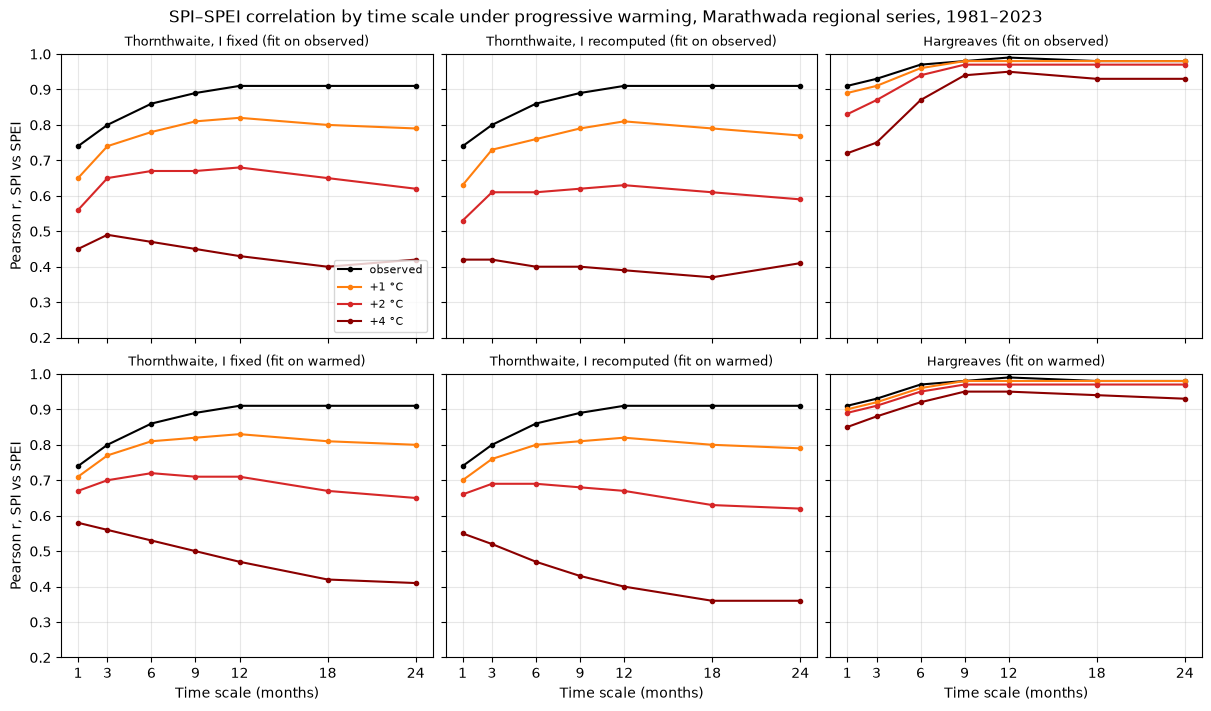

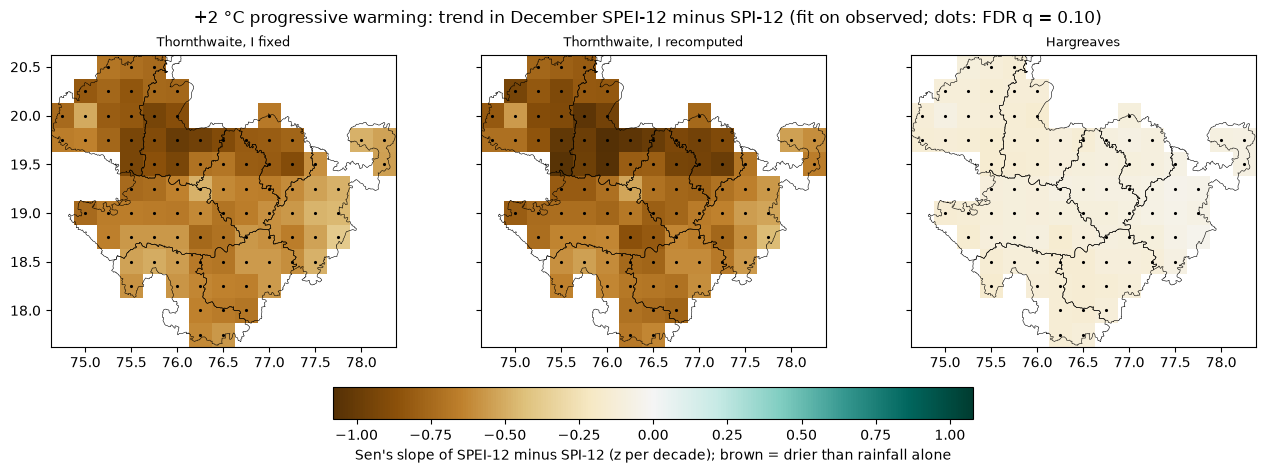

In [24]:
import matplotlib.pyplot as plt
 
SCALE_COLS = ["r1", "r3", "r6", "r9", "r12", "r18", "r24"]
SCALE_X = [1, 3, 6, 9, 12, 18, 24]
NAMES = {"th_fixed": "Thornthwaite, I fixed", "th_recalc": "Thornthwaite, I recomputed", "hg": "Hargreaves"}
COLORS = {0: "black", 1: "tab:orange", 2: "tab:red", 4: "darkred"}
 
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
for i, calib in enumerate(("ref", "self")):
    for j, var in enumerate(NAMES):
        ax = axes[i, j]
        for dt in (0, 1, 2, 4):
            row = corr[(corr.variant == var) & (corr.calib == calib) & (corr.warming == dt)].iloc[0]
            ax.plot(SCALE_X, row[SCALE_COLS].astype(float).values, "o-", ms=3, color=COLORS[dt],
                    label="observed" if dt == 0 else f"+{dt} °C")
        ax.set_title(f"{NAMES[var]} ({'fit on observed' if calib == 'ref' else 'fit on warmed'})", fontsize=9)
        ax.set_xticks(SCALE_X)
        ax.grid(alpha=0.3)
        ax.set_ylim(0.2, 1.0)
        if i == 1:
            ax.set_xlabel("Time scale (months)")
        if j == 0:
            ax.set_ylabel("Pearson r, SPI vs SPEI")
axes[0, 0].legend(fontsize=8, loc="lower right")
fig.suptitle("SPI–SPEI correlation by time scale under progressive warming, Marathwada regional series, 1981–2023")
fig.savefig("../outputs/figures/fig11_scenario_correlation.png", dpi=300)
 
# ---------- Figure 12: +2 °C trend maps of SPEI-12 minus SPI-12 ----------
import geopandas as gpd
 
districts = gpd.read_file("../data/shapefiles/marathwada_districts.gpkg")
lim = 10 * max(float(abs(grid_t[v].sel(field="slope")).max()) for v in NAMES)
 
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharex=True, sharey=True, layout="constrained")
for ax, var in zip(axes, NAMES):
    im = (grid_t[var].sel(field="slope") * 10).plot(ax=ax, cmap="BrBG", vmin=-lim, vmax=lim, add_colorbar=False)
    sig = trends.fdr(grid_t[var].sel(field="p")).stack(pt=("lat", "lon"))
    sig = sig[sig]
    ax.plot(sig.lon, sig.lat, ".", color="k", ms=2.5)
    districts.boundary.plot(ax=ax, color="k", lw=0.4)
    ax.set_title(NAMES[var], fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.colorbar(im, ax=axes, orientation="horizontal", shrink=0.5,
             label="Sen's slope of SPEI-12 minus SPI-12 (z per decade); brown = drier than rainfall alone")
fig.suptitle("+2 °C progressive warming: trend in December SPEI-12 minus SPI-12 (fit on observed; dots: FDR q = 0.10)")
fig.savefig("../outputs/figures/fig12_scenario_maps.png", dpi=300)